In [9]:

import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

API_KEY = "7704b86ee0b1aaa6881374ee195f485a"
CITY = "Pune"

print("API key configured:", bool(API_KEY))


API key configured: True


In [11]:
url = "https://api.openweathermap.org/data/2.5/forecast"

params = {
    "q": f"{CITY},IN",
    "appid": API_KEY,
    "units": "metric"
}

response = requests.get(url, params=params, timeout=20)

if response.status_code != 200:
    raise RuntimeError(
        f"API Error {response.status_code}: {response.text}"
    )

weather_data = response.json()

print("City:", weather_data["city"]["name"])
print("Country:", weather_data["city"]["country"])
print("Latitude:", weather_data["city"]["coord"]["lat"])
print("Longitude:", weather_data["city"]["coord"]["lon"])
print("Number of forecast records:", len(weather_data["list"]))

City: Pune
Country: IN
Latitude: 18.5196
Longitude: 73.8553
Number of forecast records: 40


In [13]:
records = []

for item in weather_data["list"]:
    records.append({
        "datetime": item["dt_txt"],
        "temperature": item["main"].get("temp"),
        "humidity": item["main"].get("humidity"),
        "wind_speed": item["wind"].get("speed"),
        "precipitation": item.get("rain", {}).get("3h", 0)
            + item.get("snow", {}).get("3h", 0),
        "weather": item["weather"][0].get("description"),
        "latitude": weather_data["city"]["coord"]["lat"],
        "longitude": weather_data["city"]["coord"]["lon"]
    })

df = pd.DataFrame(records)

print(df.head())
print("Shape:", df.shape)

              datetime  temperature  humidity  wind_speed  precipitation  \
0  2026-10-14 21:00:00        26.31        43        1.10            0.0   
1  2026-10-15 00:00:00        24.74        54        1.60            0.0   
2  2026-10-15 03:00:00        27.65        52        2.08            0.0   
3  2026-10-15 06:00:00        32.75        35        3.49            0.0   
4  2026-10-15 09:00:00        34.08        26        2.13            0.0   

            weather  latitude  longitude  
0         clear sky   18.5196    73.8553  
1        few clouds   18.5196    73.8553  
2  scattered clouds   18.5196    73.8553  
3  scattered clouds   18.5196    73.8553  
4   overcast clouds   18.5196    73.8553  
Shape: (40, 8)


In [15]:
df["datetime"] = pd.to_datetime(
    df["datetime"], errors="coerce"
)

numeric_columns = [
    "temperature", "humidity", "wind_speed", "precipitation"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=["datetime", "temperature", "humidity"])
df = df.drop_duplicates(subset=["datetime"])
df = df.sort_values("datetime").reset_index(drop=True)

df[numeric_columns] = df[numeric_columns].fillna(
    df[numeric_columns].median()
)

print("Missing values after cleaning:")
print(df.isnull().sum())

print("\nCleaned dataset:")
print(df.head())

Missing values after cleaning:
datetime         0
temperature      0
humidity         0
wind_speed       0
precipitation    0
weather          0
latitude         0
longitude        0
dtype: int64

Cleaned dataset:
             datetime  temperature  humidity  wind_speed  precipitation  \
0 2026-10-14 21:00:00        26.31        43        1.10            0.0   
1 2026-10-15 00:00:00        24.74        54        1.60            0.0   
2 2026-10-15 03:00:00        27.65        52        2.08            0.0   
3 2026-10-15 06:00:00        32.75        35        3.49            0.0   
4 2026-10-15 09:00:00        34.08        26        2.13            0.0   

            weather  latitude  longitude  
0         clear sky   18.5196    73.8553  
1        few clouds   18.5196    73.8553  
2  scattered clouds   18.5196    73.8553  
3  scattered clouds   18.5196    73.8553  
4   overcast clouds   18.5196    73.8553  


In [17]:
print("Weather Summary Statistics")

print(df[numeric_columns].describe().round(2))

print("\nAverage temperature:",
      round(df["temperature"].mean(), 2), "°C")

print("Maximum temperature:",
      round(df["temperature"].max(), 2), "°C")

print("Minimum temperature:",
      round(df["temperature"].min(), 2), "°C")

print("Average humidity:",
      round(df["humidity"].mean(), 2), "%")

print("Average wind speed:",
      round(df["wind_speed"].mean(), 2), "m/s")

print("Total reported precipitation:",
      round(df["precipitation"].sum(), 2), "mm")

Weather Summary Statistics
       temperature  humidity  wind_speed  precipitation
count        40.00     40.00       40.00          40.00
mean         28.10     50.70        2.11           0.00
std           3.70     12.92        1.00           0.02
min          22.44     26.00        0.31           0.00
25%          24.81     41.50        1.34           0.00
50%          27.36     53.00        1.98           0.00
75%          31.64     60.25        2.86           0.00
max          34.08     80.00        4.56           0.14

Average temperature: 28.1 °C
Maximum temperature: 34.08 °C
Minimum temperature: 22.44 °C
Average humidity: 50.7 %
Average wind speed: 2.11 m/s
Total reported precipitation: 0.14 mm


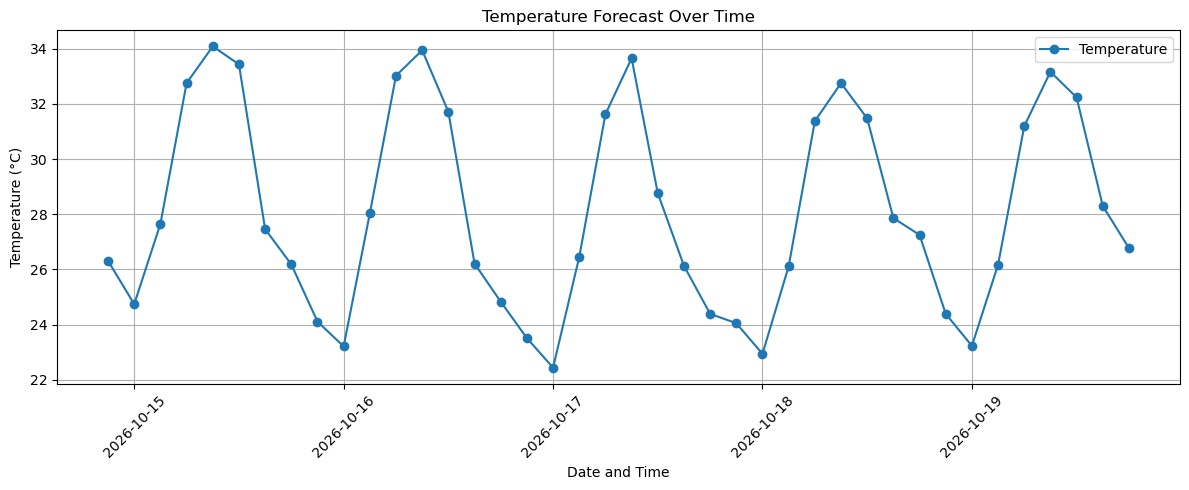

In [19]:
plt.figure(figsize=(12, 5))

plt.plot(
    df["datetime"], df["temperature"],
    marker="o", label="Temperature"
)

plt.xlabel("Date and Time")
plt.ylabel("Temperature (°C)")
plt.title("Temperature Forecast Over Time")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

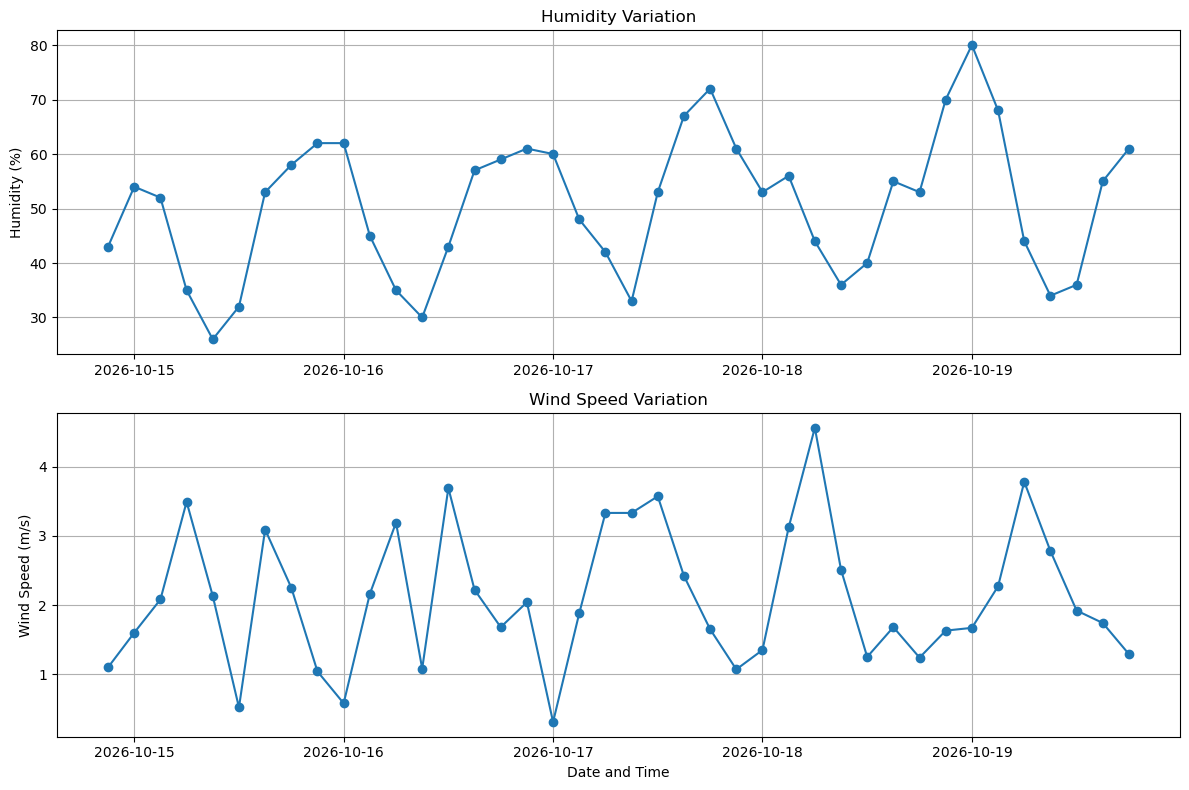

In [21]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

axes[0].plot(df["datetime"], df["humidity"], marker="o")
axes[0].set_title("Humidity Variation")
axes[0].set_ylabel("Humidity (%)")
axes[0].grid(True)

axes[1].plot(df["datetime"], df["wind_speed"], marker="o")
axes[1].set_title("Wind Speed Variation")
axes[1].set_ylabel("Wind Speed (m/s)")
axes[1].set_xlabel("Date and Time")
axes[1].grid(True)

plt.tight_layout()
plt.show()

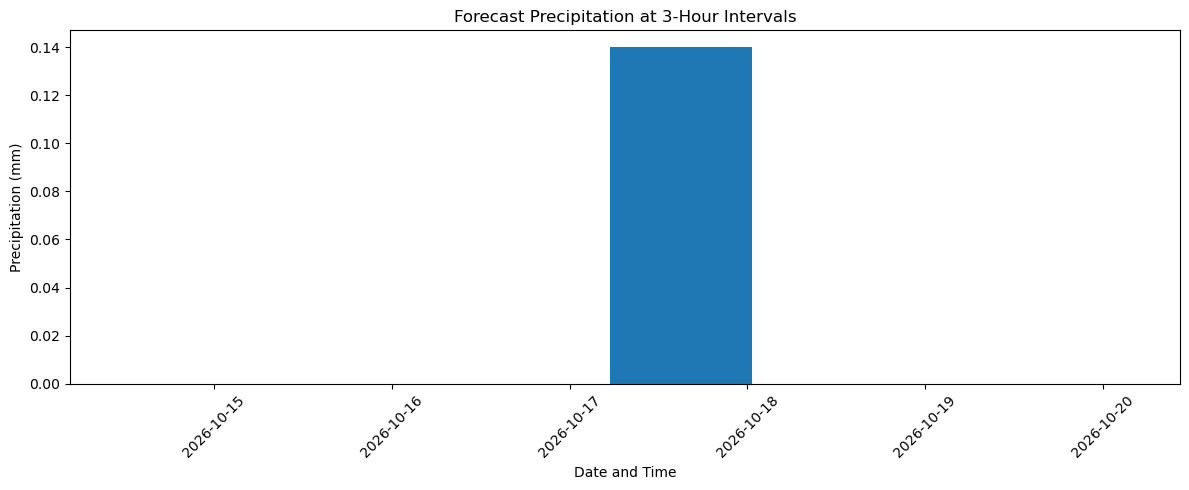

In [23]:
plt.figure(figsize=(12, 5))

plt.bar(df["datetime"], df["precipitation"])

plt.xlabel("Date and Time")
plt.ylabel("Precipitation (mm)")
plt.title("Forecast Precipitation at 3-Hour Intervals")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [25]:
df["date"] = df["datetime"].dt.date

daily_weather = df.groupby("date").agg(
    average_temperature=("temperature", "mean"),
    maximum_temperature=("temperature", "max"),
    minimum_temperature=("temperature", "min"),
    average_humidity=("humidity", "mean"),
    average_wind_speed=("wind_speed", "mean"),
    total_precipitation=("precipitation", "sum")
).reset_index()

print(daily_weather.round(2))

         date  average_temperature  maximum_temperature  minimum_temperature  \
0  2026-10-14                26.31                26.31                26.31   
1  2026-10-15                28.80                34.08                24.11   
2  2026-10-16                28.06                33.94                23.21   
3  2026-10-17                27.19                33.65                22.44   
4  2026-10-18                28.02                32.75                22.94   
5  2026-10-19                28.72                33.16                23.23   

   average_humidity  average_wind_speed  total_precipitation  
0             43.00                1.10                 0.00  
1             46.50                2.02                 0.00  
2             49.00                2.08                 0.00  
3             54.50                2.19                 0.14  
4             50.88                2.17                 0.00  
5             54.00                2.21                 0.00 

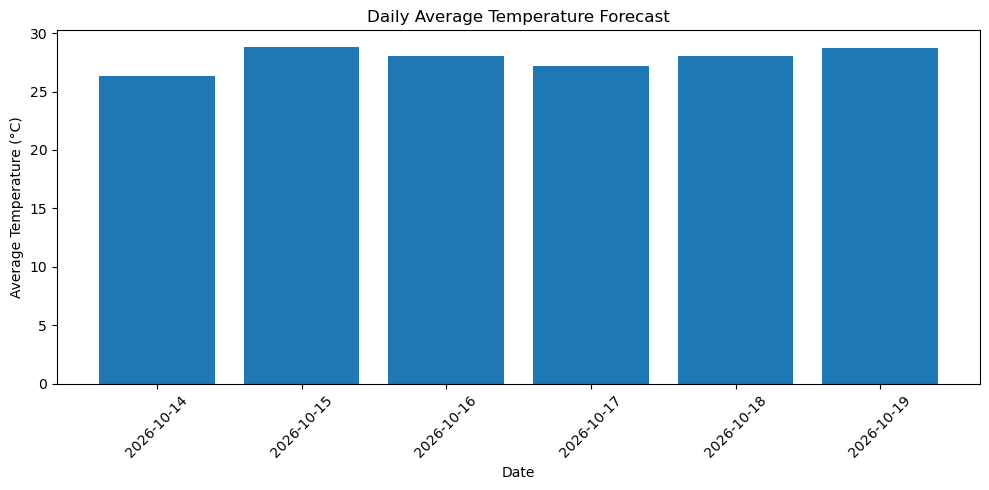

In [27]:
plt.figure(figsize=(10, 5))

plt.bar(
    daily_weather["date"].astype(str),
    daily_weather["average_temperature"]
)

plt.xlabel("Date")
plt.ylabel("Average Temperature (°C)")
plt.title("Daily Average Temperature Forecast")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

               temperature  humidity  wind_speed  precipitation
temperature           1.00     -0.89        0.48          -0.09
humidity             -0.89      1.00       -0.29           0.20
wind_speed            0.48     -0.29        1.00           0.05
precipitation        -0.09      0.20        0.05           1.00


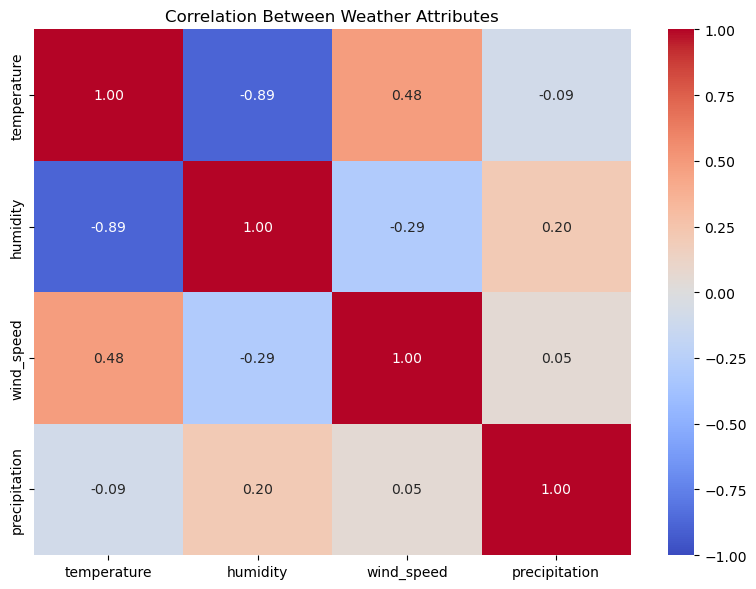

In [29]:
correlation = df[numeric_columns].corr()

print(correlation.round(2))

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Weather Attributes")
plt.tight_layout()
plt.show()

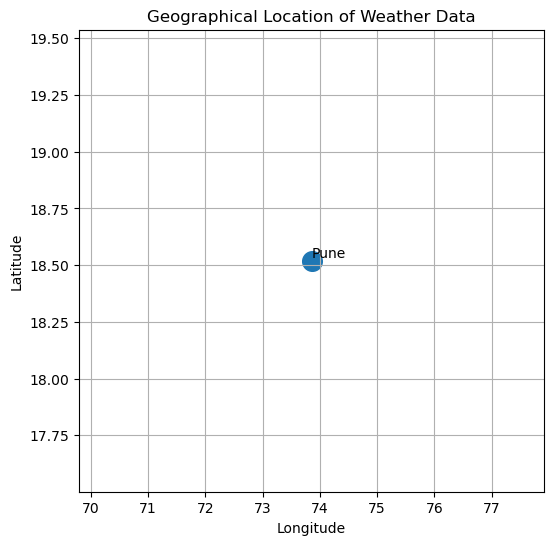

In [31]:
latitude = weather_data["city"]["coord"]["lat"]
longitude = weather_data["city"]["coord"]["lon"]

plt.figure(figsize=(6, 6))

plt.scatter(longitude, latitude, s=200, marker="o")

plt.text(longitude, latitude, CITY, ha="left", va="bottom")

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Geographical Location of Weather Data")
plt.grid(True)
plt.show()

In [33]:
df.to_csv("weather_data.csv", index=False)
daily_weather.to_csv("daily_weather_summary.csv", index=False)

print("Weather datasets saved successfully.")

Weather datasets saved successfully.
